In [1]:
from google.colab import files

uploaded = files.upload()


Saving spam_sms.csv to spam_sms (1).csv


In [3]:
!pip install -q tensorflow scikit-learn seaborn pandas matplotlib
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (5572, 2)
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Columns: ['v1', 'v2']


In [5]:
df.columns = df.columns.str.strip().str.lower()

label_col = next(
    (c for c in ["v1", "label", "category", "type", "class"]
     if c in df.columns),
    None
)

text_col = next(
    (c for c in ["v2", "message", "sms", "text", "message_text"]
     if c in df.columns),
    None
)

if label_col is None or text_col is None:
    raise ValueError(
        "Cannot identify label and message columns. "
        "Check the column names printed in Cell 3."
    )

df = df[[label_col, text_col]].copy()
df.columns = ["label", "message"]

df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[df["message"] != ""]
df = df[df["label"].isin(["ham", "spam"])]
df = df.drop_duplicates(subset=["message"])

print("Cleaned dataset shape:", df.shape)
print(df["label"].value_counts())
print(df.head())

Cleaned dataset shape: (5158, 2)
label
ham     4516
spam     642
Name: count, dtype: int64
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [7]:
sample_size = min(2000, len(df))

if df["label"].nunique() != 2:
    raise ValueError("The dataset must contain both ham and spam labels.")

if sample_size < 10:
    raise ValueError("Not enough messages to train and evaluate the model.")

if sample_size < len(df):
    df = df.groupby("label", group_keys=False).sample(
        frac=sample_size / len(df),
        random_state=42
    )

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

print("Number of messages:", len(df))
print("Ham (0) =", (df["label_num"] == 0).sum())
print("Spam (1) =", (df["label_num"] == 1).sum())

Number of messages: 2000
Ham (0) = 1751
Spam (1) = 249


In [8]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_message"] = df["message"].apply(clean_text)

print(df[["message", "clean_message", "label"]].head(10))

                                             message  \
0  Maybe i could get book out tomo then return it...   
1                             ;-( oh well, c u later   
2                Still i have not checked it da. . .   
3  INTERFLORA - åÒIt's not too late to order Inte...   
4   Free any day but i finish at 6 on mon n thurs...   
5  Sppok up ur mob with a Halloween collection of...   
6                      Alright i have a new goal now   
7  HOW ARE U? I HAVE MISSED U! I HAVENT BEEN UP 2...   
8  FreeMsg: Claim ur 250 SMS messages-Text OK to ...   
9  My mobile number.pls sms ur mail id.convey reg...   

                                       clean_message label  
0  maybe i could get book out tomo then return it...   ham  
1                                  oh well c u later   ham  
2                     still i have not checked it da   ham  
3  interflora it s not too late to order interflo...  spam  
4      free any day but i finish at 6 on mon n thurs   ham  
5  sppok up ur mo

In [9]:
X = df["clean_message"].values
y = df["label_num"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 1600
Testing messages: 400


In [10]:
max_words = 5000
max_len = 50

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Example numerical sequence:")
print(X_train_pad[0])

Training shape: (1600, 50)
Testing shape: (400, 50)
Example numerical sequence:
[   2   38  385  350  225   51  545   50  213   14  124   19  274    3
 1797   24   37   14  754   26   20    3 1798    2   57   53    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [12]:
model = Sequential([
    Embedding(input_dim=max_words, output_dim=32, mask_zero=True),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.build(input_shape=(None, 50))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,865 (659.63 KB)

 Trainable params: 168,865 (659.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8742 - loss: 0.5406 - val_accuracy: 0.8656 - val_loss: 0.4032
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8992 - loss: 0.2335 - val_accuracy: 0.9344 - val_loss: 0.2031
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9820 - loss: 0.1108 - val_accuracy: 0.9750 - val_loss: 0.1325
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9953 - loss: 0.0522 - val_accuracy: 0.9750 - val_loss: 0.0899
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9992 - loss: 0.0183 - val_accuracy: 0.9750 - val_loss: 0.1229
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9992 - loss: 0.0076 - val_accuracy: 0.9719 - val_loss: 0.1255


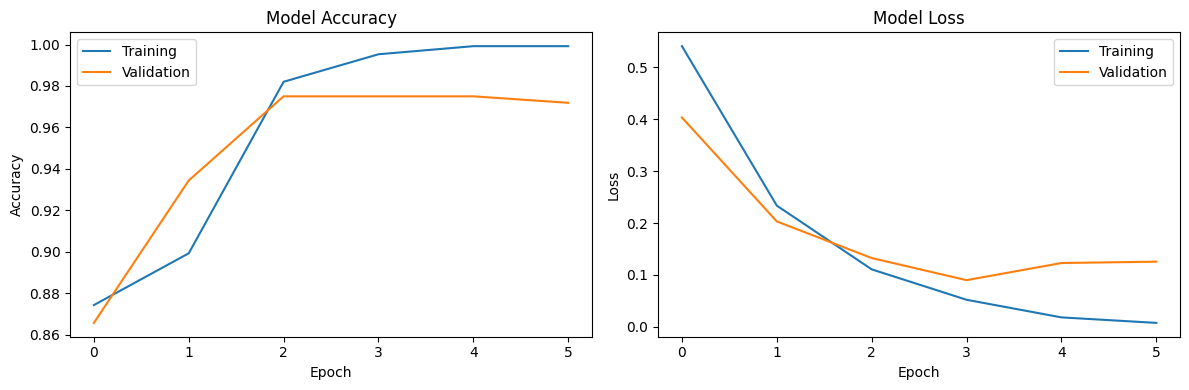

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
y_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

Accuracy : 0.985
Precision: 0.94
Recall   : 0.94
F1-score : 0.94

Classification Report:

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       350
        Spam       0.94      0.94      0.94        50

    accuracy                           0.98       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.98      0.98      0.98       400



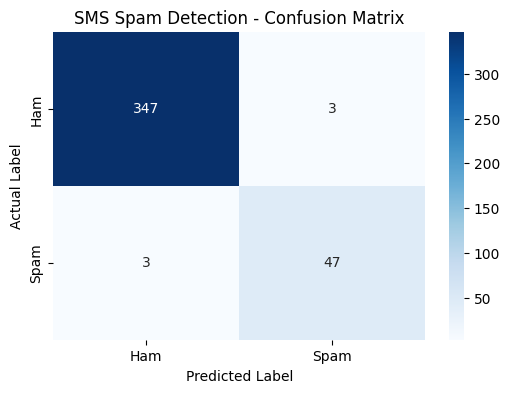

In [16]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

In [17]:
def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=max_len,
        padding="post",
        truncating="post"
    )

    probability = model.predict(padded, verbose=0)[0][0]

    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM (Normal Message)"

    print("Message:", message)
    print("Prediction:", result)
    print("Spam probability:", round(float(probability), 4))
    print("-" * 40)

predict_sms("Congratulations! You have won a free prize. Claim now!")
predict_sms("Hi, are we meeting at college tomorrow?")
predict_sms("URGENT! You have won a cash reward. Click to claim.")
predict_sms("Please bring your notebook to the lab.")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Spam probability: 0.9055
----------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: HAM (Normal Message)
Spam probability: 0.0005
----------------------------------------
Message: URGENT! You have won a cash reward. Click to claim.
Prediction: SPAM
Spam probability: 0.8596
----------------------------------------
Message: Please bring your notebook to the lab.
Prediction: HAM (Normal Message)
Spam probability: 0.3916
----------------------------------------


In [19]:
import pickle

model.save("sms_spam_lstm.keras")

with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [20]:
from google.colab import files

files.download("sms_spam_lstm.keras")
files.download("tokenizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>